In [2]:
if (!requireNamespace("mixOmics", quietly = TRUE)) {
    options(BioC_mirror = "https://bioconductor.org")
    BiocManager::install(version = "3.18", force = TRUE)
    BiocManager::install("mixOmics")
}

if (!requireNamespace("BiocParallel", quietly = TRUE)) {
    BiocManager::install("BiocParallel")
}

In [3]:
DATA_DIR <- "/home/mariya/Data/pallas/nf-core-mlomix-bimodal/finalize"
METH_FILE <- file.path(DATA_DIR, "features.dnam.csv")
GEX_FILE <- file.path(DATA_DIR, "features.gex.csv")
LABELS_FILE <- file.path(DATA_DIR, "labels.csv")
MIXOMICS_DIR <- "/home/mariya/Data/pallas/mixOmics"

In [4]:
source("helpers.R")
train_data <- data(GEX_FILE, METH_FILE, LABELS_FILE)

X_gex_train <- train_data$X_gex
X_dnam_train <- train_data$X_dnam
Y_train     <- train_data$Y

head(X_gex_train)
head(X_dnam_train)
head(Y_train)

Samples: 1200 
GEX features: 5000 
DNAm features: 5000 
Subtypes: AML, APL-PML::RARA AML, BCR::ABL1 AML, CBFA2T3::GLIS2 AML, CBFB::MYH11 AML, CEBPAalt AML, DEK::NUP214 AML, ETV6-r AML, FUS::ERG AML, KAT6A-r AML, KMT2A-r AML, NPM1alt AML, NUP98-r AML, RBM15::MKL1 AML, RUNX1::RUNX1T1 B-ALL, BCR::ABL1 B-ALL, BCR::ABL1-like B-ALL, DUX4-r B-ALL, ETV6::RUNX1 B-ALL, ETV6::RUNX1-like B-ALL, high hyperdiploid B-ALL, iAMP21 B-ALL, KMT2A-r B-ALL, MEF2D-r B-ALL, PAX5 P80R B-ALL, PAX5alt B-ALL, TCF3::PBX1 B-ALL, ZNF384-r Non-leukemic T-ALL 


,ENSG00000254772,ENSG00000196230,ENSG00000136167,ENSG00000120129,ENSG00000152518,ENSG00000130066,ENSG00000147127,ENSG00000145741,ENSG00000278677,ENSG00000116703,⋯,ENSG00000082146,ENSG00000091592,ENSG00000174898,ENSG00000152086,ENSG00000171992,ENSG00000288611,ENSG00000176438,ENSG00000223638,ENSG00000258102,ENSG00000164308
ALL_1005,12.22242,11.17626,10.160699,11.486188,6.540606,7.217236,-1.094014,9.360560,11.84936,-1.094014,⋯,6.886751,4.114954,-1.094014,-1.094014,1.0662768,-1.094014,5.458880,-1.0940139,-0.7031547,6.789474
ALL_1019,12.08865,10.54901,10.489349,12.638029,9.797654,10.625313,-1.094014,8.812944,12.20442,-1.094014,⋯,5.498455,5.397781,2.373984,-1.094014,-0.8899929,-1.094014,5.373216,1.2655482,1.4874872,6.274038
ALL_1023,12.27273,11.57122,9.064830,11.459523,10.090340,8.850153,-1.094014,8.844418,13.47757,-1.094014,⋯,6.044226,5.045265,1.616204,-1.094014,-0.7939539,-1.094014,5.853435,-0.8194423,2.3249591,6.452241
ALL_1026,12.82470,10.45617,10.432240,10.375256,9.777508,7.260263,-1.094014,9.209032,12.22074,-1.094014,⋯,6.154586,5.454379,-1.094014,-1.094014,2.1073910,-1.094014,5.397750,-1.0940139,3.8058915,4.429520
ALL_1039,12.56007,10.24231,11.143276,12.628202,9.568757,11.666583,-1.094014,9.294973,12.37270,-1.094014,⋯,4.878057,6.262360,-1.094014,-1.094014,-0.5476755,-1.094014,6.124074,-1.0940139,3.8703710,7.071240
ALL_1047,13.16769,12.19197,9.890358,9.704086,10.682779,8.398338,-1.094014,9.571006,13.40136,-1.094014,⋯,4.767217,5.308694,1.710755,-1.094014,-0.9786790,-1.094014,5.194296,-1.0940139,2.5881950,4.165885


,cg09698465,cg20439288,cg07110356,cg25670583,cg18559579,cg17353893,cg23478547,cg25588389,cg01030534,cg22301418,⋯,cg21946195,cg08233654,cg22504204,cg20232986,cg06557644,cg16530382,cg11006453,cg03430846,cg11433098,cg12691572
ALL_1005,0.6444,0.0292,0.9767,0.9345,0.9466,0.9812,0.9689,0.0184,0.0606,0.0853,⋯,0.6754,0.6514,0.9654,0.9272,0.2460,0.7725,0.9704,0.9472,0.5403,0.9257
ALL_1019,0.3499,0.0218,0.1615,0.9477,0.5065,0.9802,0.9779,0.0224,0.0402,0.0492,⋯,0.6185,0.0154,0.5325,0.9454,0.1131,0.0502,0.0491,0.7849,0.0738,0.0624
ALL_1023,0.9817,0.0167,0.9815,0.9475,0.9583,0.9842,0.9843,0.1072,0.0401,0.1176,⋯,0.5967,0.8047,0.3981,0.8947,0.1162,0.0667,0.9592,0.8576,0.0891,0.9636
ALL_1026,0.3219,0.0245,0.2155,0.9514,0.9606,0.9437,0.9824,0.0342,0.0327,0.0784,⋯,0.6373,0.0322,0.9324,0.9077,0.1178,0.0753,0.0326,0.9313,0.0690,0.0890
ALL_1039,0.9793,0.0216,0.9576,0.9485,0.9470,0.9800,0.9558,0.6030,0.0354,0.1527,⋯,0.6972,0.3196,0.2391,0.2638,0.1710,0.0695,0.8935,0.4152,0.2011,0.7794
ALL_1047,0.9705,0.0298,0.9758,0.9202,0.9368,0.9748,0.9772,0.0323,0.1199,0.0366,⋯,0.9406,0.9241,0.9720,0.8959,0.0362,0.1035,0.9439,0.9385,0.0379,0.9378


[1] B-ALL, MEF2D-r          B-ALL, ZNF384-r         B-ALL, ETV6::RUNX1     
[4] B-ALL, PAX5alt          B-ALL, BCR::ABL1        B-ALL, ETV6::RUNX1-like
29 Levels: AML, APL-PML::RARA AML, BCR::ABL1 ... T-ALL

In [5]:
library(mixOmics)
library(caret)
library(BiocParallel)

Loading required package: MASS

Loading required package: lattice

Loading required package: ggplot2


Loaded mixOmics 6.26.0
Thank you for using mixOmics!
Tutorials: http://mixomics.org
Bookdown vignette: https://mixomicsteam.github.io/Bookdown
Questions, issues: Follow the prompts at http://mixomics.org/contact-us
Cite us:  citation('mixOmics')



Attaching package: ‘caret’


The following objects are masked from ‘package:mixOmics’:

    nearZeroVar, plsda, splsda




In [6]:
gex_perf <- readRDS(file.path(MIXOMICS_DIR, "gex_perf.rds"))
dnam_perf <- readRDS(file.path(MIXOMICS_DIR, "dnam_perf.rds"))
diablo_perf <- readRDS(file.path(MIXOMICS_DIR, "diablo_perf.rds"))

In [26]:
comp_num <- 35

gex_ber    <- gex_perf$error.rate.class$max.dist[, paste0("comp", comp_num)]
dnam_ber   <- dnam_perf$error.rate.class$max.dist[, paste0("comp", comp_num)]
diablo_ber <- rowMeans(cbind(
  diablo_perf$error.rate.per.class$GEX$max.dist[,  paste0("comp", comp_num)],
  diablo_perf$error.rate.per.class$DNAm$max.dist[, paste0("comp", comp_num)]
))

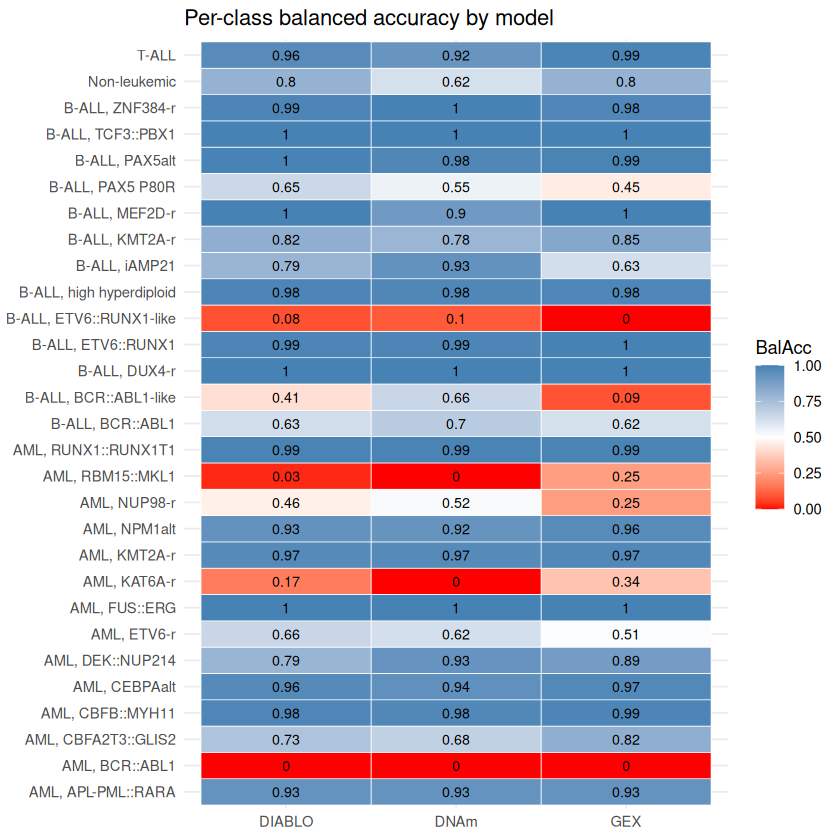

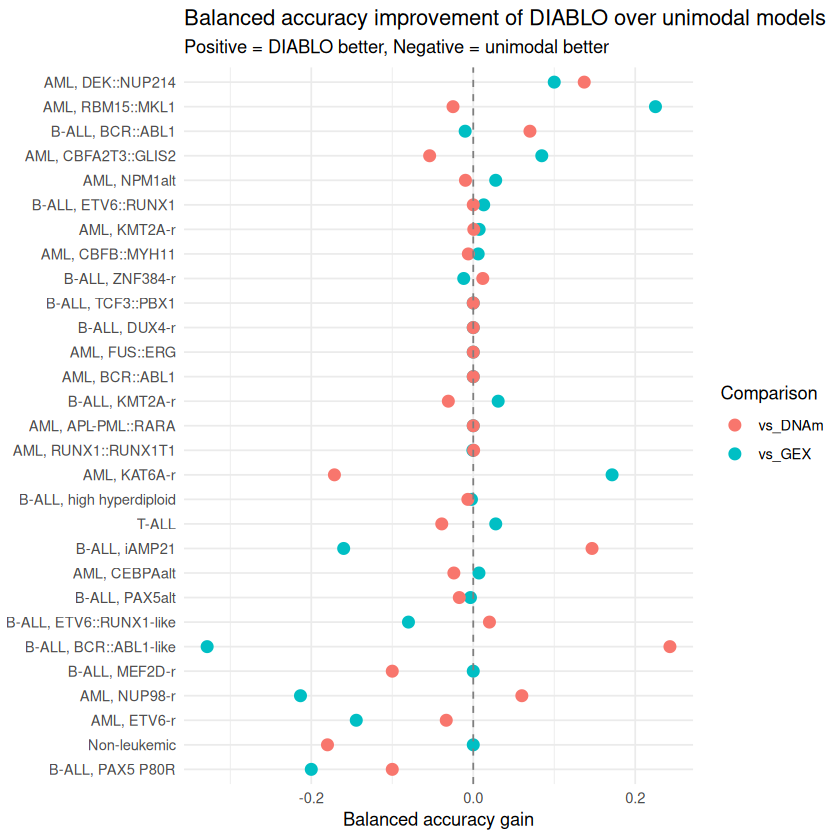

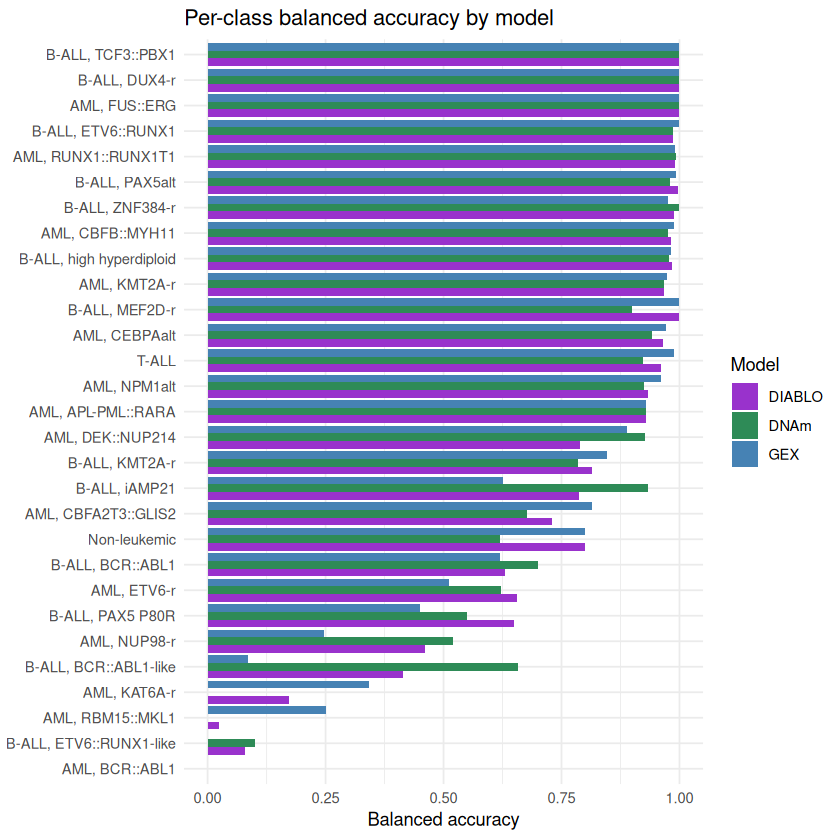

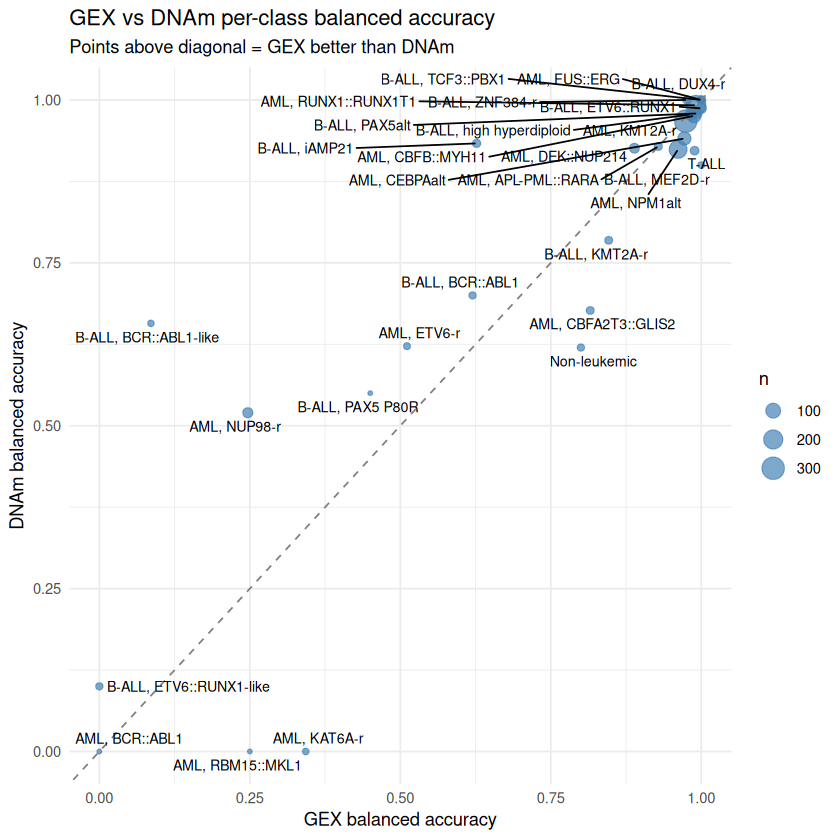

In [27]:
library(ggplot2)
library(tidyr)
library(dplyr)
library(ggrepel)

# ============================================================
# Convert to balanced accuracy
# ============================================================
bacc_df <- data.frame(
  Class  = names(gex_ber),
  GEX    = 1 - as.numeric(gex_ber),
  DNAm   = 1 - as.numeric(dnam_ber),
  DIABLO = 1 - as.numeric(diablo_ber)
)

bacc_long <- pivot_longer(bacc_df, cols = c("GEX","DNAm","DIABLO"),
                          names_to = "Model", values_to = "BalAcc")

# ============================================================
# 1. Heatmap
# ============================================================
ggplot(bacc_long, aes(x = Model, y = Class, fill = BalAcc)) +
  geom_tile(colour = "white") +
  scale_fill_gradient2(low = "red", mid = "white", high = "steelblue",
                       midpoint = 0.5, limits = c(0, 1)) +
  geom_text(aes(label = round(BalAcc, 2)), size = 3) +
  labs(title = "Per-class balanced accuracy by model", x = NULL, y = NULL) +
  theme_minimal()

# ============================================================
# 2. Dot plot — improvement of DIABLO over unimodal
# ============================================================
improve_df <- data.frame(
  Class   = names(gex_ber),
  vs_GEX  = as.numeric(diablo_ber) - as.numeric(gex_ber),   # flipped vs before
  vs_DNAm = as.numeric(diablo_ber) - as.numeric(dnam_ber)
) |>
  pivot_longer(cols = c("vs_GEX","vs_DNAm"),
               names_to  = "Comparison",
               values_to = "BalAcc_improvement")

ggplot(improve_df, aes(x = BalAcc_improvement,
                       y = reorder(Class, BalAcc_improvement),
                       colour = Comparison)) +
  geom_point(size = 3) +
  geom_vline(xintercept = 0, linetype = "dashed", colour = "grey50") +
  labs(title    = "Balanced accuracy improvement of DIABLO over unimodal models",
       subtitle = "Positive = DIABLO better, Negative = unimodal better",
       x = "Balanced accuracy gain", y = NULL) +
  theme_minimal()

# ============================================================
# 3. Bar chart sorted by DIABLO balanced accuracy
# ============================================================
ggplot(bacc_long, aes(x = reorder(Class, BalAcc), y = BalAcc, fill = Model)) +
  geom_bar(stat = "identity", position = "dodge") +
  scale_fill_manual(values = c(GEX = "steelblue", DNAm = "seagreen", DIABLO = "darkorchid")) +
  coord_flip() +
  labs(title = "Per-class balanced accuracy by model", x = NULL, y = "Balanced accuracy") +
  theme_minimal()

# ============================================================
# 4. Scatter — GEX vs DNAm balanced accuracy, sized by n
# ============================================================
class_sizes <- as.data.frame(table(Y_train))
colnames(class_sizes) <- c("Class", "n")

bacc_df <- left_join(bacc_df, class_sizes, by = "Class")

ggplot(bacc_df, aes(x = GEX, y = DNAm, size = n, label = Class)) +
  geom_point(alpha = 0.7, colour = "steelblue") +
  geom_abline(slope = 1, intercept = 0, linetype = "dashed", colour = "grey50") +
  ggrepel::geom_text_repel(size = 3, max.overlaps = 20) +
  labs(title    = "GEX vs DNAm per-class balanced accuracy",
       subtitle = "Points above diagonal = GEX better than DNAm",
       x = "GEX balanced accuracy", y = "DNAm balanced accuracy") +
  theme_minimal()

In [28]:
# ============================================================
# Overall summary
# ============================================================
overall <- data.frame(
  Model        = c("GEX", "DNAm", "DIABLO"),
  Mean_BalAcc  = round(c(mean(bacc_df$GEX),
                          mean(bacc_df$DNAm),
                          mean(bacc_df$DIABLO)), 3),
  Median_BalAcc = round(c(median(bacc_df$GEX),
                           median(bacc_df$DNAm),
                           median(bacc_df$DIABLO)), 3),
  Min_BalAcc   = round(c(min(bacc_df$GEX),
                          min(bacc_df$DNAm),
                          min(bacc_df$DIABLO)), 3),
  Max_BalAcc   = round(c(max(bacc_df$GEX),
                          max(bacc_df$DNAm),
                          max(bacc_df$DIABLO)), 3),
  Classes_above_0.5 = c(sum(bacc_df$GEX    > 0.5),
                         sum(bacc_df$DNAm   > 0.5),
                         sum(bacc_df$DIABLO > 0.5))
)
print(overall)

# ============================================================
# How many classes does DIABLO win/tie/lose vs each unimodal?
# ============================================================
cat("\n=== DIABLO vs GEX ===\n")
cat("DIABLO better: ", sum(bacc_df$DIABLO >  bacc_df$GEX),  "\n")
cat("Tied:          ", sum(bacc_df$DIABLO == bacc_df$GEX),  "\n")
cat("GEX better:    ", sum(bacc_df$DIABLO <  bacc_df$GEX),  "\n")

cat("\n=== DIABLO vs DNAm ===\n")
cat("DIABLO better: ", sum(bacc_df$DIABLO >  bacc_df$DNAm), "\n")
cat("Tied:          ", sum(bacc_df$DIABLO == bacc_df$DNAm), "\n")
cat("DNAm better:   ", sum(bacc_df$DIABLO <  bacc_df$DNAm), "\n")

# ============================================================
# Wilcoxon signed-rank test — is DIABLO significantly better?
# ============================================================
cat("\n=== Wilcoxon signed-rank test ===\n")
wt_gex  <- wilcox.test(bacc_df$DIABLO, bacc_df$GEX,
                        paired = TRUE, alternative = "greater")
wt_dnam <- wilcox.test(bacc_df$DIABLO, bacc_df$DNAm,
                        paired = TRUE, alternative = "greater")

cat("DIABLO vs GEX  p-value:", round(wt_gex$p.value,  4), "\n")
cat("DIABLO vs DNAm p-value:", round(wt_dnam$p.value, 4), "\n")

   Model Mean_BalAcc Median_BalAcc Min_BalAcc Max_BalAcc Classes_above_0.5
1    GEX       0.732         0.929          0          1                22
2   DNAm       0.744         0.924          0          1                25
3 DIABLO       0.748         0.929          0          1                23

=== DIABLO vs GEX ===
DIABLO better:  11 
Tied:           7 
GEX better:     11 

=== DIABLO vs DNAm ===
DIABLO better:  14 
Tied:           6 
DNAm better:    9 

=== Wilcoxon signed-rank test ===


Warning message in wilcox.test.default(bacc_df$DIABLO, bacc_df$GEX, paired = TRUE, :
“cannot compute exact p-value with zeroes”
Warning message in wilcox.test.default(bacc_df$DIABLO, bacc_df$DNAm, paired = TRUE, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(bacc_df$DIABLO, bacc_df$DNAm, paired = TRUE, :
“cannot compute exact p-value with zeroes”


DIABLO vs GEX  p-value: 0.4871 
DIABLO vs DNAm p-value: 0.2014 


In [29]:
# Is DIABLO at least consistently competitive? (not worse)
wt_gex_two  <- wilcox.test(bacc_df$DIABLO, bacc_df$GEX,  paired = TRUE)
wt_dnam_two <- wilcox.test(bacc_df$DIABLO, bacc_df$DNAm, paired = TRUE)
cat("Two-sided DIABLO vs GEX  p-value:", round(wt_gex_two$p.value,  4), "\n")
cat("Two-sided DIABLO vs DNAm p-value:", round(wt_dnam_two$p.value, 4), "\n")

Warning message in wilcox.test.default(bacc_df$DIABLO, bacc_df$GEX, paired = TRUE):
“cannot compute exact p-value with zeroes”
Warning message in wilcox.test.default(bacc_df$DIABLO, bacc_df$DNAm, paired = TRUE):
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(bacc_df$DIABLO, bacc_df$DNAm, paired = TRUE):
“cannot compute exact p-value with zeroes”


Two-sided DIABLO vs GEX  p-value: 0.9741 
Two-sided DIABLO vs DNAm p-value: 0.4029 


In [30]:
# For each class, take the better of GEX or DNAm
oracle_bacc <- pmax(bacc_df$GEX, bacc_df$DNAm)

oracle_summary <- data.frame(
  Model       = c("GEX", "DNAm", "DIABLO", "Oracle (best unimodal)"),
  Mean_BalAcc = round(c(mean(bacc_df$GEX),
                         mean(bacc_df$DNAm),
                         mean(bacc_df$DIABLO),
                         mean(oracle_bacc)), 3)
)
print(oracle_summary)

# Which modality wins per class?
bacc_df$Best_modality <- ifelse(bacc_df$GEX >= bacc_df$DNAm, "GEX", "DNAm")
print(bacc_df[, c("Class", "GEX", "DNAm", "Best_modality")])

                   Model Mean_BalAcc
1                    GEX       0.732
2                   DNAm       0.744
3                 DIABLO       0.748
4 Oracle (best unimodal)       0.788
                      Class        GEX      DNAm Best_modality
1        AML, APL-PML::RARA 0.92857143 0.9285714           GEX
2            AML, BCR::ABL1 0.00000000 0.0000000           GEX
3       AML, CBFA2T3::GLIS2 0.81538462 0.6769231           GEX
4          AML, CBFB::MYH11 0.98780488 0.9756098           GEX
5             AML, CEBPAalt 0.97183099 0.9408451           GEX
6          AML, DEK::NUP214 0.88888889 0.9259259          DNAm
7               AML, ETV6-r 0.51111111 0.6222222          DNAm
8             AML, FUS::ERG 1.00000000 1.0000000           GEX
9              AML, KAT6A-r 0.34285714 0.0000000           GEX
10             AML, KMT2A-r 0.97417219 0.9675497           GEX
11             AML, NPM1alt 0.96144578 0.9240964           GEX
12             AML, NUP98-r 0.24666667 0.5200000          D

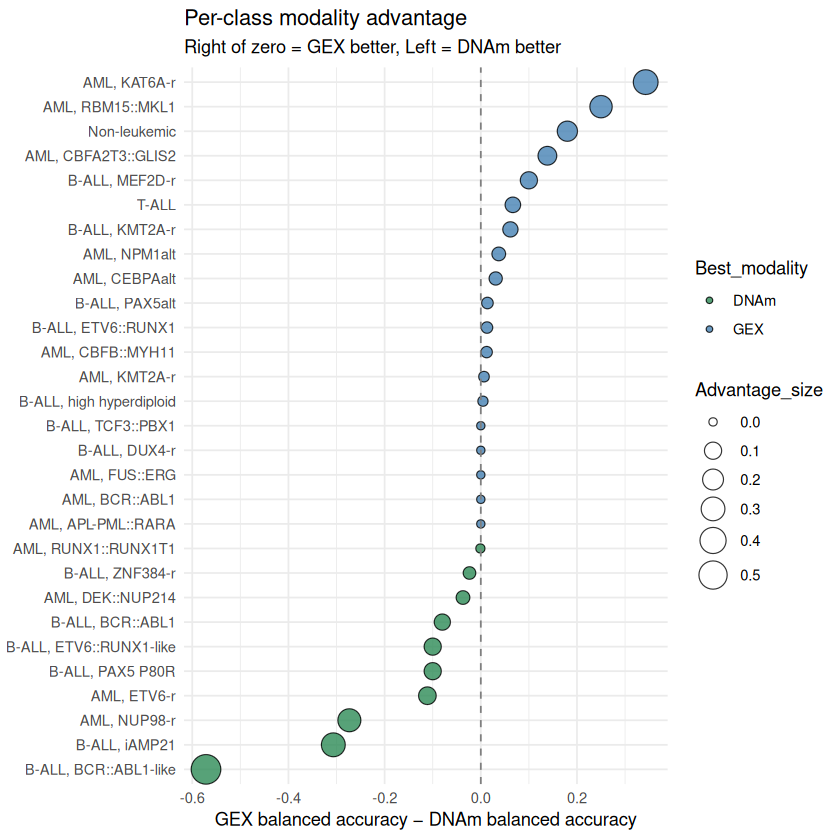

In [31]:
complement_df <- bacc_df |>
  mutate(
    GEX_advantage  = GEX  - DNAm,
    Best_modality  = ifelse(GEX >= DNAm, "GEX", "DNAm"),
    Advantage_size = abs(GEX - DNAm)
  ) |>
  arrange(GEX_advantage)

ggplot(complement_df,
       aes(x = GEX_advantage,
           y = reorder(Class, GEX_advantage),
           fill = Best_modality,
           size = Advantage_size)) +
  geom_point(shape = 21, alpha = 0.8) +
  geom_vline(xintercept = 0, linetype = "dashed", colour = "grey50") +
  scale_fill_manual(values = c(GEX = "steelblue", DNAm = "seagreen")) +
  scale_size_continuous(range = c(2, 8)) +
  labs(title    = "Per-class modality advantage",
       subtitle = "Right of zero = GEX better, Left = DNAm better",
       x = "GEX balanced accuracy − DNAm balanced accuracy",
       y = NULL) +
  theme_minimal()